# Library

In [ ]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay, ConfusionMatrixDisplay

In [4]:
import kagglehub
import os

# Download dataset dari Kaggle (sekali saja, selanjutnya di-cache)
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

# File utama sesuai ketentuan tugas
csv_path = os.path.join(path, "creditcard.csv")
print("CSV path:", csv_path)

# Import menggunakan pandas
df = pd.read_csv(csv_path)

Path to dataset files: C:\Users\LAPTOPKU\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3
CSV path: C:\Users\LAPTOPKU\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3\creditcard.csv


# EDA

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [7]:
df.shape

(284807, 31)

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


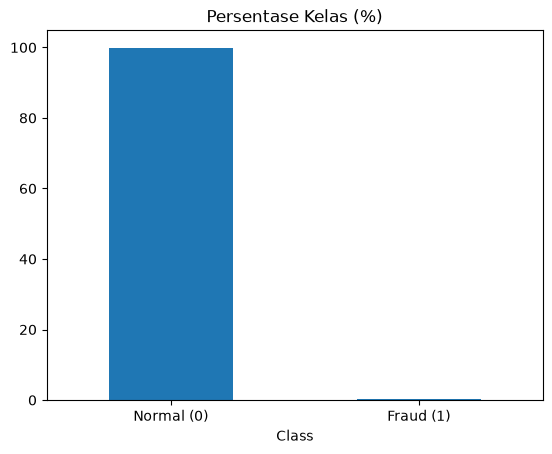

In [8]:
jumlah = df['Class'].value_counts()
persen = df['Class'].value_counts(normalize=True) * 100

print(jumlah)
print(persen)

persen.plot(kind='bar')
plt.title('Persentase Kelas (%)')
plt.xticks([0,1], ['Normal (0)', 'Fraud (1)'], rotation=0)
plt.show()

# Preprocessing

In [9]:
X = df.drop(columns=['Class'])
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
from imblearn.over_sampling import SMOTE

# Resampling HANYA pada data latih, data uji tetap distribusi asli
print("Sebelum SMOTE (train):")
print(pd.Series(y_train).value_counts())

smote = SMOTE(sampling_strategy=0.2, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("\nSesudah SMOTE (train):")
print(pd.Series(y_train_res).value_counts())

print("\nData uji (tetap asli, jangan di-resample):")
print(pd.Series(y_test).value_counts())

Sebelum SMOTE (train):
Class
0    227451
1       394
Name: count, dtype: int64

Sesudah SMOTE (train):
Class
0    227451
1     45490
Name: count, dtype: int64

Data uji (tetap asli, jangan di-resample):
Class
0    56864
1       98
Name: count, dtype: int64


# Modeling - Random Forest: Tanpa vs Dengan SMOTE

In [ ]:
# Model 1: TANPA penanganan imbalance (latih di X_train asli)
rf_baseline = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    n_jobs=-1)
    
rf_baseline.fit(X_train, y_train)

# Prediksi di data uji yang SAMA (distribusi asli)
y_pred_baseline = rf_baseline.predict(X_test)
y_proba_baseline = rf_baseline.predict_proba(X_test)[:, 1]
print("Baseline selesai")

Baseline selesai


In [ ]:
# Model 2: DENGAN SMOTE (latih di X_train_res yang sudah seimbang)
rf_smote = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    n_jobs=-1)
    
rf_smote.fit(X_train_res, y_train_res)

# Prediksi di data uji yang SAMA (tetap asli, jangan pakai data resample!)
y_pred_smote = rf_smote.predict(X_test)
y_proba_smote = rf_smote.predict_proba(X_test)[:, 1]
print("SMOTE selesai")

SMOTE selesai


In [21]:
# Bandingkan sekilas (detail precision/recall/AUC di langkah Evaluasi)
from sklearn.metrics import classification_report

print("=== Baseline (tanpa SMOTE) ===")
print(classification_report(y_test, y_pred_baseline, digits=4))

print("=== Dengan SMOTE ===")
print(classification_report(y_test, y_pred_smote, digits=4))

=== Baseline (tanpa SMOTE) ===
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962

=== Dengan SMOTE ===
              precision    recall  f1-score   support

           0     0.9998    0.9997    0.9998     56864
           1     0.8500    0.8673    0.8586        98

    accuracy                         0.9995     56962
   macro avg     0.9249    0.9335    0.9292     56962
weighted avg     0.9995    0.9995    0.9995     56962



## 4. Evaluasi Model (fokus kelas 1 = fraud)

In [22]:
# Hitung precision, recall, F1, AUC khusus kelas minoritas (1)
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

hasil = pd.DataFrame({
    "Baseline": [
        precision_score(y_test, y_pred_baseline, pos_label=1),
        recall_score(y_test, y_pred_baseline, pos_label=1),
        f1_score(y_test, y_pred_baseline, pos_label=1),
        roc_auc_score(y_test, y_proba_baseline)
    ],
    "SMOTE": [
        precision_score(y_test, y_pred_smote, pos_label=1),
        recall_score(y_test, y_pred_smote, pos_label=1),
        f1_score(y_test, y_pred_smote, pos_label=1),
        roc_auc_score(y_test, y_proba_smote)
    ]
}, index=["precision_1", "recall_1", "f1_1", "auc_roc"])
display(hasil.round(4))

,Baseline,SMOTE
precision_1,0.9412,0.8500
recall_1,0.8163,0.8673
f1_1,0.8743,0.8586
auc_roc,0.9630,0.9793


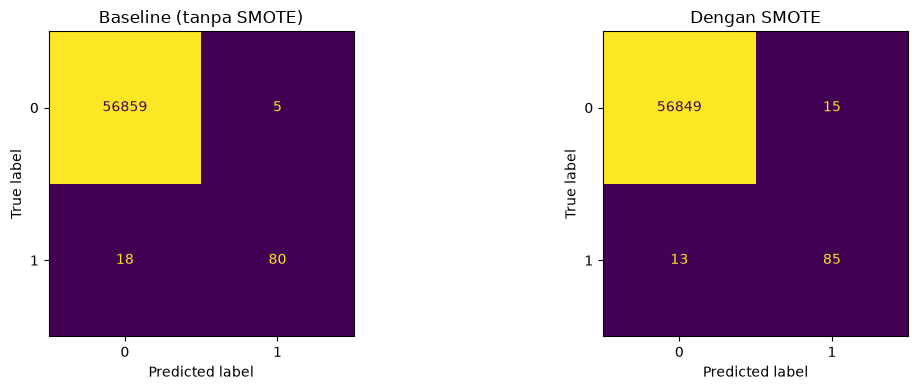

In [23]:
# Confusion matrix untuk memahami distribusi prediksi
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_baseline, ax=ax[0], colorbar=False)
ax[0].set_title("Baseline (tanpa SMOTE)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote, ax=ax[1], colorbar=False)
ax[1].set_title("Dengan SMOTE")
plt.tight_layout()
plt.show()

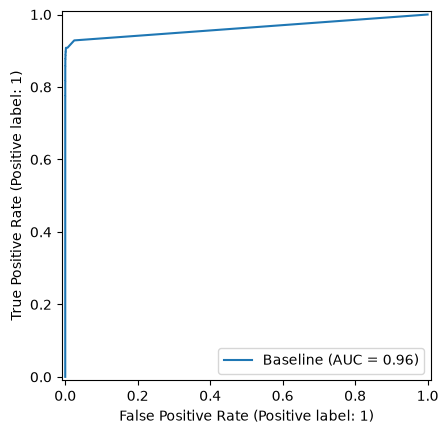

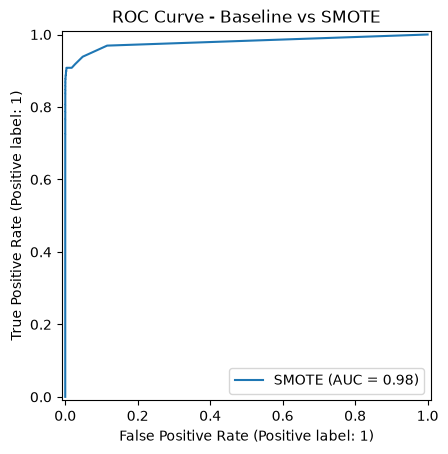

In [24]:
# Kurva ROC untuk kedua model
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_proba_baseline, name="Baseline")
RocCurveDisplay.from_predictions(y_test, y_proba_smote, name="SMOTE")
plt.title("ROC Curve - Baseline vs SMOTE")
plt.show()

Hasil: 

Baseline precision 0.94, recall 0.81, F1 0.87, AUC 0.963. 

SMOTE precision 0.85, recall 0.86, F1 0.85, AUC 0.979.

Analisis:

SMOTE menaikkan recall/AUC (lebih banyak fraud ketangkap) tapi menurunkan precision (lebih banyak false alarm) -> trade-off wajar.

Kenapa accuracy saja tidak cukup: accuracy ~99.9% di kedua model menipu, karena kalau model nebak semua transaksi normal pun langsung dapat 99.8% (284315/284807). Accuracy didominasi kelas mayoritas, sehingga gagal mengukur kegagalan di kelas fraud yang justru paling penting.